In [ ]:
pip install imagen-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 kB 903.6 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.6/302.6 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 917.8/917.8 kB 12.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 41.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.4/825.4 kB 44.1 MB/s eta 0:00:00
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (23.7 MB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (823 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (14.1 MB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl (731.7 MB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl (410.6 MB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl

In [3]:
pip install imagen-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 82.3 MB/s eta 0:00:00


In [4]:
import torch
from imagen_pytorch import Unet, Imagen, ImagenTrainer

# unet for imagen with reduced complexity
unet1 = Unet(
    dim = 16,  # reduced dimensionality
    cond_dim = 512,
    dim_mults = (1, 2),  # reduced number of dimensions
    num_resnet_blocks = 2,  # reduced number of resnet blocks
    layer_attns = (False, True),
)

# imagen, simplified with fewer timesteps
imagen = Imagen(
    unets = (unet1,),
    text_encoder_name = 't5-small',  # smaller text encoder
    image_sizes = (64,),  # smaller image size
    timesteps = 100,  # reduced timesteps
    cond_drop_prob = 0.1
)

# wrap imagen with the trainer class
trainer = ImagenTrainer(imagen)

# mock text embeddings from smaller T5 and images
text_embeds = torch.randn(4, 256, 512)  # smaller batch size
images = torch.randn(4, 3, 64, 64)  # smaller image size

# feed images into imagen, training the unet
loss = trainer(images, text_embeds = text_embeds, unet_number = 1)

trainer.update(unet_number = 1)

# Now, let's add the sampling code with your text prompts
# Sample images based on the text prompts
sampled_images = trainer.sample(texts = [
    'a puppy looking anxiously at a giant donut on the table',
    'the milky way galaxy in the style of monet'
], cond_scale = 3.)

print(sampled_images.shape) # (2, 3, 64, 64)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

The base dimension of your u-net should ideally be no smaller than 128, as recommended by a professional DDPM trainer https://nonint.com/2022/05/04/friends-dont-let-friends-train-small-diffusion-models/


config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/imagen_pytorch/trainer.py:346: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled = grad_scaler_enabled)


model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/51 [00:00<?, ?it/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

AttributeError: T5Tokenizer has no attribute batch_encode_plus

In [1]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# Function to convert tensor to image and display it
def show_tensor_images(image_tensor, num_images=2, size=(64, 64)):
    # Check if the tensor has the correct shape (N, C, H, W)
    if image_tensor.dim() == 4 and image_tensor.shape[1] == 3:
        # Normalize the tensor to [0, 1]
        image_tensor = (image_tensor + 1) / 2
        # Clamp the values to ensure they are between 0 and 1
        image_tensor = image_tensor.clamp(0, 1)
        # Make a grid and display it
        image_grid = make_grid(image_tensor[:num_images], nrow=num_images)
        plt.imshow(image_grid.permute(1, 2, 0).squeeze())
        plt.show()
    else:
        print("The tensor does not have the correct shape for an image.")

# Assuming 'sampled_images' is your tensor with generated images
show_tensor_images(sampled_images)

NameError: name 'sampled_images' is not defined

In [ ]:
import torch
from imagen_pytorch import Unet, Imagen, ImagenTrainer

# unet for imagen with reduced complexity
unet1 = Unet(
    dim = 16,  # reduced dimensionality
    cond_dim = 512,
    dim_mults = (1, 2),  # reduced number of dimensions
    num_resnet_blocks = 2,  # reduced number of resnet blocks
    layer_attns = (False, True),
)

# imagen, simplified with fewer timesteps
imagen = Imagen(
    unets = (unet1,),
    text_encoder_name = 't5-small',  # smaller text encoder
    image_sizes = (64,),  # smaller image size
    timesteps = 100,  # reduced timesteps
    cond_drop_prob = 0.1
)

# wrap imagen with the trainer class
trainer = ImagenTrainer(imagen)

# mock text embeddings from smaller T5 and images
text_embeds = torch.randn(4, 256, 512)  # smaller batch size
images = torch.randn(4, 3, 64, 64)  # smaller image size

# feed images into imagen, training the unet
loss = trainer(images, text_embeds = text_embeds, unet_number = 1)

trainer.update(unet_number = 1)

# Now, let's add the sampling code with your text prompts
# Sample images based on the text prompts
sampled_images = trainer.sample(texts = [
    'a puppy looking anxiously at a giant donut on the table',
    'the milky way galaxy in the style of monet'
], cond_scale = 3.)

print(sampled_images.shape) # (2, 3, 64, 64)


/usr/local/lib/python3.10/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

The base dimension of your u-net should ideally be no smaller than 128, as recommended by a professional DDPM trainer https://nonint.com/2022/05/04/friends-dont-let-friends-train-small-diffusion-models/


/usr/local/lib/python3.10/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/accelerate/accelerator.py:446: FutureWarning: Passing the following arguments to `Accelerator` is deprecated and will be removed in version 1.0 of Accelerate: dict_keys(['split_batches']). Please pass an `accelerate.DataLoaderConfiguration` instead: 
dataloader_config = DataLoaderConfiguration(split_batches=True)
  warnings.warn(


... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

0it [00:00, ?it/s]

sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

torch.Size([2, 3, 64, 64])


In [ ]:
!pip install matplotlib

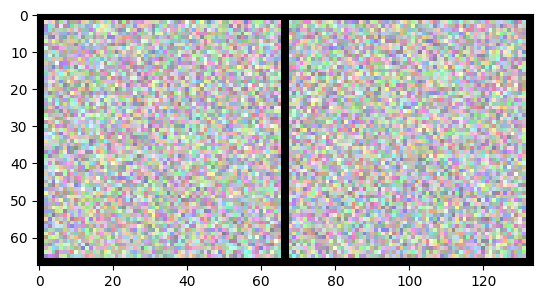

In [ ]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# Function to convert tensor to image and display it
def show_tensor_images(image_tensor, num_images=2, size=(64, 64)):
    # Check if the tensor has the correct shape (N, C, H, W)
    if image_tensor.dim() == 4 and image_tensor.shape[1] == 3:
        # Normalize the tensor to [0, 1]
        image_tensor = (image_tensor + 1) / 2
        # Clamp the values to ensure they are between 0 and 1
        image_tensor = image_tensor.clamp(0, 1)
        # Make a grid and display it
        image_grid = make_grid(image_tensor[:num_images], nrow=num_images)
        plt.imshow(image_grid.permute(1, 2, 0).squeeze())
        plt.show()
    else:
        print("The tensor does not have the correct shape for an image.")

# Assuming 'sampled_images' is your tensor with generated images
show_tensor_images(sampled_images)
